# Checkpoint 2

Estimating the location and extent of slow conduction regions in the heart is a classic inverse problem in cardiac electrophysiology. In this checkpoint, you will use mathematical modeling and computational techniques to estimate the position and radius of slow conduction areas from activation times annotated on electrogram measurements (see Checkpoint 1).

A key tool for this task is the **eikonal equation**, a simplified model of cardiac electrophysiology that describes activation time as a function of spatial coordinates. The eikonal formulation provides a fast and efficient way to reconstruct activation patterns, making it well suited for PDE-constrained optimization, physics-informed neural networks, and the generation of in silico datasets for scientific machine learning.

Using one of these approaches, you will estimate the location and size of slow conduction regions—by minimizing the discrepancy between simulated and observed activation times.
You will also account for unknown tissue properties, including conduction velocity and anisotropy, which play a crucial role in wavefront propagation. The velocity of slow conduction areas is assumed to be common across all patients and therefore needs to be estimated only once.


In [1]:
# imports

import numpy as np
import matplotlib.pyplot as plt


# Physics-based model implementation

Implemenatation of the algorithm presented in :

Sermesant, Maxime, et al. "An anisotropic multi-front fast marching method for real-time simulation of cardiac electrophysiology." Functional Imaging and Modeling of the Heart: 4th International Conference, FIHM 2007, Salt Lake City, UT, USA, June 7-9, 2007. Proceedings 4. Springer Berlin Heidelberg, 2007.

In [ ]:
import numpy as np
import heapq

def anisotropic_FMM_GPT(
    x0, y0, t0,
    X, Y,
    speed_input,
    sigma_11, sigma_12, sigma_22,
    N_edge=None
):
    """
    Fast-marching style solver with anisotropy and spatially varying speed.

    Parameters
    ----------
    x0, y0 : float
        Initial source location.
    t0 : float
        Initial activation time.
    X, Y : 2D ndarray
        Grid coordinates.
    speed_input : float, callable, or 2D ndarray
        Can be:
        - a scalar: constant speed everywhere
        - a function: speed_input(x, y)
        - a 2D array with same shape as X, Y
    sigma_11, sigma_12, sigma_22 : float
        Components of the inverse of conductivity tensor.
    N_edge : int or None
        Optional. If None, inferred from grid shape.

    Returns
    -------
    T_final : 2D ndarray
        Arrival time map.
    """

    nrows, ncols = X.shape
    if N_edge is None:
        N_edge = nrows - 1

    INF = 1e4
    P = np.linspace(0.0, 1.0, 11)

    # nearest grid node to source
    j0 = np.abs(X[0, :] - x0).argmin()
    i0 = np.abs(Y[:, 0] - y0).argmin()

    T = np.full((nrows, ncols), INF, dtype=float)
    T_final = np.full((nrows, ncols), INF, dtype=float)

    T[i0, j0] = t0
    T_final[i0, j0] = t0

    known = np.zeros((nrows, ncols), dtype=bool)

    # min-heap of (arrival_time, i, j)
    heap = [(t0, i0, j0)]

    def get_speed(i, j, x, y):
        if callable(speed_input):
            val = speed_input(x, y)
        elif np.isscalar(speed_input):
            val = speed_input
        else:
            val = speed_input[i, j]

        if val <= 0:
            raise ValueError(f"Speed must be positive. Got {val} at ({i}, {j}).")
        return val

    def metric_dist(xa, ya, xb, yb, speed_val):
        dx = xa - xb
        dy = ya - yb
        return np.sqrt(
            sigma_11 * dx * dx +
            2.0 * sigma_12 * dx * dy +
            sigma_22 * dy * dy
        ) / speed_val

    def update_fun(
        T_xi, T_x, T_y,
        X_xi, X_x, X_y,
        Y_xi, Y_x, Y_y,
        flag_known,
        i_xi, j_xi
    ):
        speed_val = get_speed(i_xi, j_xi, X_xi, Y_xi)

        if flag_known:
            dx = P * (X_xi - X_x) + (1.0 - P) * (X_xi - X_y)
            dy = P * (Y_xi - Y_x) + (1.0 - P) * (Y_xi - Y_y)

            triangle_vals = (
                P * T_x + (1.0 - P) * T_y
                + np.sqrt(
                    sigma_11 * dx * dx +
                    2.0 * sigma_12 * dx * dy +
                    sigma_22 * dy * dy
                ) / speed_val
            )
            cand = triangle_vals.min()
        else:
            cand = T_x + metric_dist(X_xi, Y_xi, X_x, Y_x, speed_val)

        return min(T_xi, cand)

    # side nodes used for triangle updates
    side_map = {
        (-1,  0): [(-1, +1), (-1, -1)],  # north
        (+1,  0): [(+1, +1), (+1, -1)],  # south
        ( 0, -1): [(+1, -1), (-1, -1)],  # west
        ( 0, +1): [(+1, +1), (-1, +1)],  # east
    }

    while heap:
        t_sel, i_sel, j_sel = heapq.heappop(heap)

        # ignore stale entries
        if known[i_sel, j_sel]:
            continue
        if t_sel > T_final[i_sel, j_sel]:
            continue

        known[i_sel, j_sel] = True

        # visit 4-neighbors
        for di, dj in [(-1, 0), (1, 0), (0, -1), (0, +1)]:
            ni, nj = i_sel + di, j_sel + dj

            if not (0 <= ni < nrows and 0 <= nj < ncols):
                continue
            if known[ni, nj]:
                continue

            new_T = INF

            for sdi, sdj in side_map[(di, dj)]:
                si, sj = i_sel + sdi, j_sel + sdj

                if not (0 <= si < nrows and 0 <= sj < ncols):
                    continue

                new_T = update_fun(
                    T_xi=new_T,
                    T_x=T_final[i_sel, j_sel],
                    T_y=T_final[si, sj],
                    X_xi=X[ni, nj], X_x=X[i_sel, j_sel], X_y=X[si, sj],
                    Y_xi=Y[ni, nj], Y_x=Y[i_sel, j_sel], Y_y=Y[si, sj],
                    flag_known=known[si, sj],
                    i_xi=ni, j_xi=nj
                )

            if new_T < T_final[ni, nj]:
                T[ni, nj] = new_T
                T_final[ni, nj] = new_T
                heapq.heappush(heap, (new_T, ni, nj))

    return T_final

# Eikonal equation

Let us consider the Eikonal model: find T(x,y)

\begin{aligned}
  & 80 \sqrt{ \nabla T(x,y) D \nabla T(x,y)} = 1  \,, \quad (x,y) \in [-2,2] \times [-2,2]\,,\\
  & u(x,y) = t_0,t_1  \,, \qquad \qquad \qquad \qquad \qquad x=x_0,x_1,y=y_0,y_1 \,, \\
\end{aligned}

where 
\begin{aligned}
D = 1\ \vec{b} \otimes \vec{b} + \frac{1}{a_{ratio}}  \ \vec{a} \otimes \vec{a},
\end{aligned}
being $ \vec{b} $ the given fiber orientation and $ \vec{a} $ the given cross-fiber orientation (orthogonal to $ \vec{b}$).

The unknown parameters of the problem are: 
- conduction velocity (tissue property common to all the patients),
- anisotropy ratio $a_{ratio}$ (tissue property common to all the patients),
- the slow conduction positions $(x_{SC},y_{SC})$ and its radius $r_{SC}$.

In [ ]:
X_mesh, Y_mesh = np.meshgrid(np.linspace(-2.0,2.0,401), np.linspace(-2.0,2.0,401))

x0 = -1.5
y0 = -1

theta_fiber = 0
a_ratio = 5

theta0 = np.pi/2 - theta_fiber
a = np.array([np.cos(theta0), np.sin(theta0)]).T
b = np.array([np.cos(theta0-np.pi/2), np.sin(theta0-np.pi/2)]).T

D = ( (1/a_ratio)*np.tensordot( a, a,  axes=0) + np.tensordot( b, b,  axes=0)  )
print(D)

D_inv = np.linalg.inv(D)
sigma_11 = D_inv[0][0]
sigma_12 = D_inv[0][1]
sigma_21 = D_inv[1][0]
sigma_22 = D_inv[1][1]

xc, yc = 0.5, 0.5
r = 0.5

speed_field = lambda x, y: 20.0 if (x - xc)**2 + (y - yc)**2 <= r**2 else 80.0

activation_time = anisotropic_FMM_GPT( x0 , y0 , 0, X_mesh, Y_mesh, speed_field, sigma_11,sigma_12, sigma_22, N_edge=200 )




[[1.0000000e+00 1.2246468e-17]
 [1.2246468e-17 2.0000000e-01]]


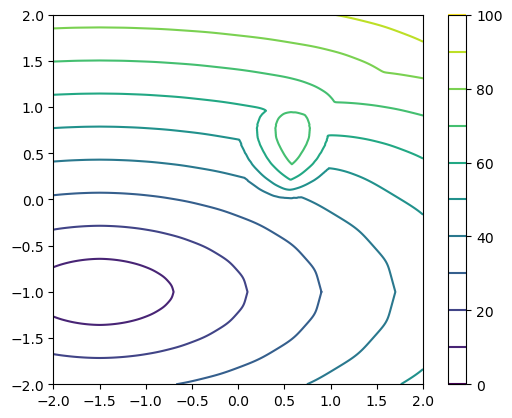

In [ ]:

plt.contour(X_mesh, Y_mesh, activation_time*1000 , 10) 
plt.gca().set_aspect(1)
plt.colorbar()

In [ ]:
N_samples = 1

np.random.seed(32)

measurements_dataset = []
groundtruth_dataset = []

for i_sample in range(N_samples):

    x0 = np.random.uniform(low=1.5,high=1.5)
    y0 = np.random.uniform(low=-1.5,high=1.5)
    x1 = np.random.uniform(low=1.5,high=1.5)
    y1 = np.random.uniform(low=-1.5,high=1.5)
    theta_fiber = 0.0
    a_ratio = np.random.uniform(low=1,high=9)

    theta0 = np.pi/2 - theta_fiber
    a = np.array([np.cos(theta0), np.sin(theta0)]).T
    b = np.array([np.cos(theta0-np.pi/2), np.sin(theta0-np.pi/2)]).T

    D = ( (1/a_ratio)*np.tensordot( a, a,  axes=0) + np.tensordot( b, b,  axes=0)  )
    print(D)

    D_inv = np.linalg.inv(D)
    sigma_11 = D_inv[0][0]
    sigma_12 = D_inv[0][1]
    sigma_21 = D_inv[1][0]
    sigma_22 = D_inv[1][1]

    # compute activation time
    activation_time = anisotropic_FMM_GPT( x0 , y0 , 0.0, X_mesh, Y_mesh, speed_field, sigma_11,sigma_12, sigma_22, N_edge=200 )

    # rescaling in ms
    activation_time = activation_time*1e3

    # measurements location
    Spline_spacing = [0.5, 0.7, 1.3, 1.5]
    Angles_spacing =  [np.pi/10.0+0, np.pi/10.0+(2)*np.pi/5, np.pi/10.0+(4)*np.pi/5, np.pi/10.0+(6)*np.pi/5, np.pi/10.0+(8)*np.pi/5 ]
    
    index_extracted = []
    x_meas = []
    y_meas = []
    time_meas = []

    for j in range(5):
        for i in range(4):
            MeasMat = (X_mesh - Spline_spacing[i]*np.cos(Angles_spacing[j]) )**2 + (Y_mesh - Spline_spacing[i]*np.sin(Angles_spacing[j]) )**2
            [i_sel, j_sel] = np.unravel_index(MeasMat.argmin(), MeasMat.shape) 
            index_extracted.append(i_sel)
            x_meas.append(X_mesh[i_sel,j_sel])
            y_meas.append(Y_mesh[i_sel,j_sel])
            time_meas.append(activation_time[i_sel,j_sel])

    measurements_dataset.append( [ x_meas, y_meas, time_meas ] )
    groundtruth_dataset.append([activation_time])

[[1.00000000e+00 8.88280440e-18]
 [8.88280440e-18 1.45067205e-01]]


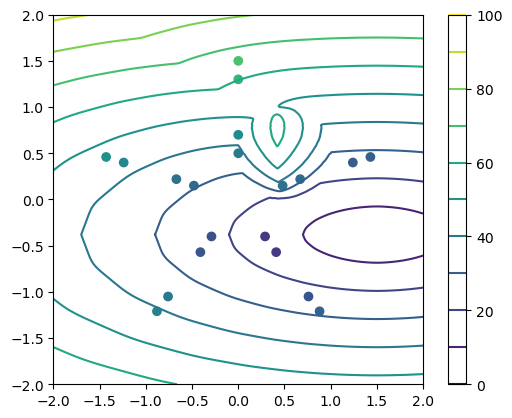

In [ ]:
plt.figure(1)
plt.scatter( x_meas, y_meas, c=time_meas, vmin= 0, vmax=np.max(activation_time) )
plt.contour(X_mesh, Y_mesh, activation_time , 10)
plt.gca().set_aspect(1)
plt.colorbar()

# Checkpoint 2

Implement your algorithm to process the traces of the 20 unipolar electrogram signals and identify the center and radius of the slow conduction region.

The algorithm must return the following outputs:

1. **slow conduction center** 
2. **slow conduction radius**

Therefore output should be in the following form:
[x_SC,y_SC,r_SC] 

Provide your algorithm's implementation in this notebook usign the signature defined below.

In [ ]:
# load data
signals = np.load('checkpoint2dataset.npy')

# select event to be display
ind_event = 0

signals_event = signals[ind_event,:,:]

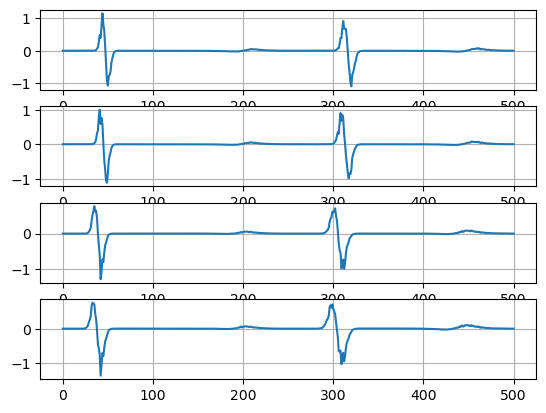

In [ ]:
# select a spline (options: 0,1,2,3,4)
ind_spline = 0
# plot signals

plt.figure(1+ind_spline)
countEL = 1
for indS in np.arange(ind_spline*4,(ind_spline+1)*4,1):
    plt.subplot(4,1,countEL)
            
    plt.plot(signals[ind_event,indS,:])
    plt.grid(True)

    countEL = countEL + 1

plt.show()

In [ ]:
# known starting points (to test your algorithm)
# Note that a rescaling with respect to the center is needed
impulse_sites = np.load('checkpoint2FocalPoints.npy')
[x0,y0] = impulse_sites[0][0]
[x1,y1] = impulse_sites[0][1]

# t_0, t_1 can be extracted from the file: "checkpoint2starting.npy"

In [ ]:
import numpy as np
from scipy.optimize import minimize
from scipy.signal import argrelextrema, savgol_filter
from tqdm import tqdm  # <-- IMPORTANTE: Aggiunto per la barra di progresso
import warnings
warnings.filterwarnings("ignore")

# ==========================================
# 0. FUNZIONE ESTRAZIONE TEMPI (DA CP1)
# ==========================================
def GroupSolutionCP1(signals_event):
    sig_filtered = savgol_filter(signals_event, window_length=11, polyorder=3, axis=1)
    n_sensors = sig_filtered.shape[0]
    timings = []
    min_dist = 100 
    
    for i in range(n_sensors):
        ds = np.gradient(sig_filtered[i, :])
        min_indices = argrelextrema(ds, np.less)[0]
        
        selected = []
        if len(min_indices) > 0:
            depths = ds[min_indices]
            sorted_args = np.argsort(depths)
            candidates = min_indices[sorted_args]
            
            for idx in candidates:
                if len(selected) == 0:
                    selected.append(idx)
                elif len(selected) == 1:
                    if abs(idx - selected[0]) >= min_dist:
                        selected.append(idx)
                        break
            selected.sort()

        row_time = [None, None]
        for j in range(min(len(selected), 2)):
            row_time[j] = int(selected[j])
        
        row_final = [t if t is not None else np.nan for t in row_time]
        timings.append(row_final)

    return timings

# ==========================================
# 1. SETUP SPAZIALE
# ==========================================
X_mesh, Y_mesh = np.meshgrid(np.linspace(-2.0, 2.0, 401), np.linspace(-2.0, 2.0, 401))
X_mesh_vel, Y_mesh_vel = np.meshgrid(np.linspace(-2.0, 2.0, 201), np.linspace(-2.0, 2.0, 201))
X_mesh_100, Y_mesh_100 = np.meshgrid(np.linspace(-2.0, 2.0, 101), np.linspace(-2.0, 2.0, 101))
Spline_spacing = [0.5, 0.7, 1.3, 1.5]
Angles_spacing = [np.pi/10.0+0, np.pi/10.0+(2)*np.pi/5, np.pi/10.0+(4)*np.pi/5, np.pi/10.0+(6)*np.pi/5, np.pi/10.0+(8)*np.pi/5]

meas_indices = []
for j in range(5):
    for i in range(4):
        MeasMat = (X_mesh - Spline_spacing[i]*np.cos(Angles_spacing[j]))**2 + (Y_mesh - Spline_spacing[i]*np.sin(Angles_spacing[j]))**2
        i_sel, j_sel = np.unravel_index(MeasMat.argmin(), MeasMat.shape)
        meas_indices.append((i_sel, j_sel))

meas_indices_vel = []
for j in range(5):
    for i in range(4):
        MeasMat_vel = (X_mesh_vel - Spline_spacing[i]*np.cos(Angles_spacing[j]))**2 + (Y_mesh_vel - Spline_spacing[i]*np.sin(Angles_spacing[j]))**2
        i_sel, j_sel = np.unravel_index(MeasMat_vel.argmin(), MeasMat_vel.shape)
        meas_indices_vel.append((i_sel, j_sel))

meas_indices_100 = []
for j in range(5):
    for i in range(4):
        MeasMat_100 = (X_mesh_100 - Spline_spacing[i]*np.cos(Angles_spacing[j]))**2 + (Y_mesh_100 - Spline_spacing[i]*np.sin(Angles_spacing[j]))**2
        i_sel, j_sel = np.unravel_index(MeasMat_100.argmin(), MeasMat_100.shape)
        meas_indices_100.append((i_sel, j_sel))

# ==========================================
# 2. CARICAMENTO DATI UFFICIALI
# ==========================================
signals = np.load('checkpoint2dataset.npy') 
impulse_sites = np.load('checkpoint2FocalPoints.npy') 
starting_times = np.load('checkpoint2starting.npy') 

# INSERISCI I DATI REALI forniti per l'anisotropia
a_ratios_training = np.load('checkpoint2anisotropy.npy')

reference_targets = [
    [-0.407, 0.299, 0.578],
    [0.81, 0.113, 0.394],
    [-0.816, -0.686, 0.274],
    [0.197, -0.242, 0.042],
    [0.647, -0.69, 0.244]
] 

# ==========================================
# 3. PRE-ESTRAZIONE TEMPI MISURATI (CORRETTA)
# ==========================================
measured_times_beat1 = []
measured_times_beat2 = []

for idx_event in range(5):
    raw_timings = GroupSolutionCP1(signals[idx_event, :, :])
    
    # Se la correlazione era negativa, significa che i 4 sensori di ogni spline
    # nel dataset sono invertiti rispetto a Spline_spacing.
    
    t_beat1_ordered = []
    t_beat2_ordered = []
    
    for s in range(5): # Per ogni spline
        # Prendi i 4 tempi della spline s
        spline_times = raw_timings[s*4 : (s+1)*4]
        
        # PROVA A INVERTIRE QUI: 
        # Se il dataset è [Lontano -> Vicino], invertiamo per farlo diventare [Vicino -> Lontano]
        spline_times = spline_times[::-1] 
        
        for t in spline_times:
            t_beat1_ordered.append(t[0])
            t_beat2_ordered.append(t[1])
            
    measured_times_beat1.append(np.array(t_beat1_ordered, dtype=float))
    measured_times_beat2.append(np.array(t_beat2_ordered, dtype=float))

# ==========================================
# 4. FUNZIONE OBIETTIVO CON VELOCITÀ SFUMATA (TANH)
# ==========================================
def objective_velocities(velocities):
    v_base, v_slow = velocities
    total_mse = 0.0
    
    for idx in range(5):
        xc, yc, r = reference_targets[idx]
        a_ratio = a_ratios_training[idx]**2
        
        # 1. Costruzione tensore di diffusione (Anisotropia)
        theta0 = np.pi/2 # fiber_theta assumed 0
        a = np.array([np.cos(theta0), np.sin(theta0)])
        b = np.array([np.cos(theta0-np.pi/2), np.sin(theta0-np.pi/2)])
        D = ((1/a_ratio)*np.outer(a, a) + np.outer(b, b))
        D_inv = np.linalg.inv(D)
        sigma_11, sigma_12, sigma_22 = D_inv[0,0], D_inv[0,1], D_inv[1,1]
        
        # 2. CREAZIONE CAMPO VELOCITÀ
        speed_field = lambda x, y: v_slow if (x - xc)**2 + (y - yc)**2 <= r**2 else v_base
        
        # --- SIMULAZIONE BATTITO 1 ---
        x0, y0 = impulse_sites[idx][0]
        t0 = starting_times[idx][0]/1000.0 # convertiamo in secondi
        
        sim_beat1 = anisotropic_FMM_GPT(
            x0, y0, t0, X_mesh_vel, Y_mesh_vel, speed_field, 
            sigma_11, sigma_12, sigma_22
        ) * 1000.0
        
        sim_times1 = np.array([sim_beat1[i, j] for i, j in meas_indices_vel])
        meas_times1 = measured_times_beat1[idx]
        
        mask1 = ~np.isnan(meas_times1)
        if np.any(mask1):
            total_mse += np.mean((sim_times1[mask1] - meas_times1[mask1])**2)
            
        # --- SIMULAZIONE BATTITO 2 ---
        x1, y1 = impulse_sites[idx][1]
        t1 = starting_times[idx][1]/1000.0
        
        sim_beat2 = anisotropic_FMM_GPT(
            x1, y1, t1, X_mesh_vel, Y_mesh_vel, speed_field, 
            sigma_11, sigma_12, sigma_22
        ) * 1000.0
        
        sim_times2 = np.array([sim_beat2[i, j] for i, j in meas_indices_vel])
        meas_times2 = measured_times_beat2[idx]

        mask2 = ~np.isnan(meas_times2)
        if np.any(mask2):
            total_mse += np.mean((sim_times2[mask2] - meas_times2[mask2])**2)
        
    return total_mse

In [ ]:
# # ==========================================
# # 5. AVVIO OTTIMIZZAZIONE
# # ==========================================
# initial_guess = [80.0, 20.0] 
# bounds = [(40.0, 150.0), (5.0, 40.0)] 

# print("Inizio calibrazione delle velocità (su 2 battiti per paziente)...")
# result = minimize(objective_velocities, initial_guess, method='Nelder-Mead', bounds=bounds, options={'xatol': 1.0, 'fatol': 0.1})

# if result.success:
#     print(f"\n✅ Ottimizzazione convergente!")
#     print(f"Velocità tessuto sano (v_base): {result.x[0]:.2f}")
#     print(f"Velocità tessuto lento (v_slow): {result.x[1]:.2f}")
# else:
#     print("\n❌ L'ottimizzatore non ha trovato un minimo:", result.message)


# Assicurati di definire un initial_guess (es. v_base, v_slow iniziali)
initial_guess = [80, 20] 
bounds = [(40.0, 150.0), (5.0, 40.0)] 

# Inizializza la barra di progresso di tqdm
# Usa un formato che mostra il conteggio (poiché il totale non è noto)
pbar = tqdm(desc="Valutazioni Funzione Obiettivo", unit="eval")

# Funzione wrapper per aggiornare la barra ad ogni chiamata
def objective_with_pbar(velocities):
    pbar.update(1)
    # Mostra i valori correnti in tempo reale nella barra
    pbar.set_postfix({"v_base": f"{velocities[0]:.3f}", "v_slow": f"{velocities[1]:.3f}"})
    return objective_velocities(velocities)

# Lancia l'ottimizzazione
print("Inizio ottimizzazione...")
result = minimize(
    objective_with_pbar, 
    initial_guess, 
    method='Nelder-Mead', # O il metodo che preferisci (L-BFGS-B, Powell, ecc.)
    bounds=bounds, # Scommenta se vuoi impostare limiti di ricerca
    options={'xatol': 1.0, 'fatol': 0.1}
)

# Chiudi la barra di progresso al termine
pbar.close()

print("\nOttimizzazione completata!")
print("Migliori parametri trovati:")
print(f"v_base = {result.x[0]:.4f}")
print(f"v_slow = {result.x[1]:.4f}")
print(f"MSE Finale = {result.fun:.4f}")

Valutazioni Funzione Obiettivo: 1eval [00:00, 700.22eval/s, v_base=80.000, v_slow=20.000]

Inizio ottimizzazione...


Valutazioni Funzione Obiettivo: 34eval [12:20, 21.78s/eval, v_base=65.391, v_slow=23.670]


Ottimizzazione completata!
Migliori parametri trovati:
v_base = 65.3906
v_slow = 23.6699
MSE Finale = 812.3314


In [ ]:
# 6. SALVATAGGIO DELLE VELOCITÀ STIMATE
# ==========================================
# Estraiamo le velocità in modo automatico dall'ottimizzazione precedente
if result.success:
    EST_V_BASE = result.x[0]
    EST_V_SLOW = result.x[1]

sim_rel [0.04506209 0.04756893 0.05587622 0.05869475 0.0608293  0.06252652
 0.07928192 0.08535544 0.06360375 0.0603013  0.05431906 0.05699021
 0.0268621  0.02238641 0.01237679 0.01237436 0.02777517 0.02383135
 0.01618771 0.016651  ]
meas_rel [38. 39. 45. 48. 57. 61. 70. 74. 51. 54. 49. 49. 23. 19. 10. 10. 23. 19.
 13. 14.]
48.98819932052952
sim_rel2 [0.29476373 0.29782125 0.30769736 0.31092603 0.30953567 0.31123289
 0.32798829 0.33406181 0.30917537 0.30589452 0.2999523  0.30268689
 0.27370081 0.26841662 0.28054232 0.28579874 0.28032947 0.28019839
 0.29003225 0.29454628]
meas_rel2 [305. 305. 313. 316. 327. 334. 343. 348. 315. 315. 312. 312. 280. 266.
 280. 286. 283. 282. 290. 294.]
92.91981857758535
--- VERIFICA SPAZIALE SCENARIO 1 ---
Sensore | Tempo Reale (ms) | Distanza dallo Stimolo (mesh)
--------------------------------------------------
      0 |            38.00 |                    1.5264
      1 |            39.00 |                    1.6600
      2 |            45.00 |       

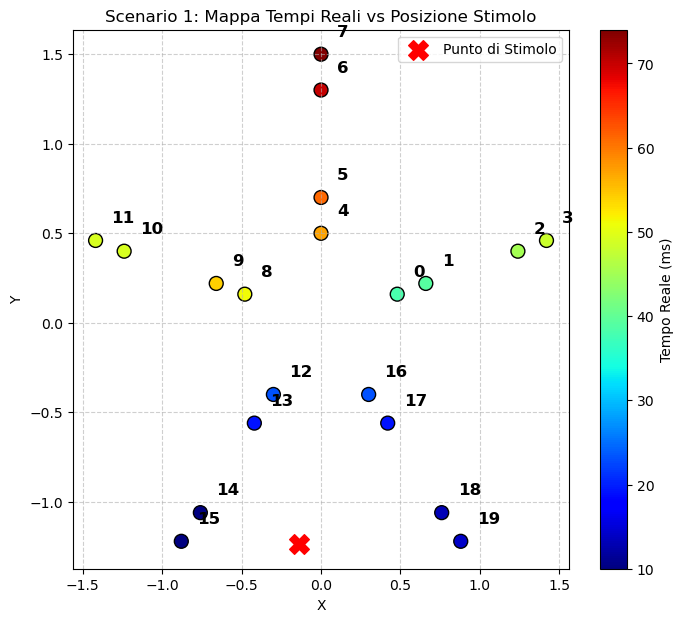

sim_rel [0.01892783 0.02787273 0.04371608 0.04429243 0.02789583 0.03702979
 0.06450811 0.07367504 0.01382253 0.01768108 0.02976303 0.03368222
 0.01796695 0.02555638 0.04912426 0.0567023  0.01943997 0.02692507
 0.05030483 0.05786798]
meas_rel [17. 23. 44. 48. 22. 29. 51. 58.  9. 13. 23. 26. 13. 19. 38. 44. 15. 20.
 39. 45.]
71.62167482784284
sim_rel2 [0.33760451 0.34687794 0.35115118 0.35418309 0.34839046 0.35746706
 0.38480303 0.39392686 0.33200429 0.33458093 0.34314102 0.34618586
 0.30689128 0.29932748 0.27583997 0.26865864 0.30953747 0.30360216
 0.28950822 0.28771301]
meas_rel2 [343. 350. 365. 362. 346. 355. 378. 385. 331. 334. 341. 344. 309. 302.
 280. 272. 312. 308. 296. 294.]
29.368267691764704
--- VERIFICA SPAZIALE SCENARIO 2 ---
Sensore | Tempo Reale (ms) | Distanza dallo Stimolo (mesh)
--------------------------------------------------
      0 |            17.00 |                    0.6508
      1 |            23.00 |                    0.8405
      2 |            44.00 |      

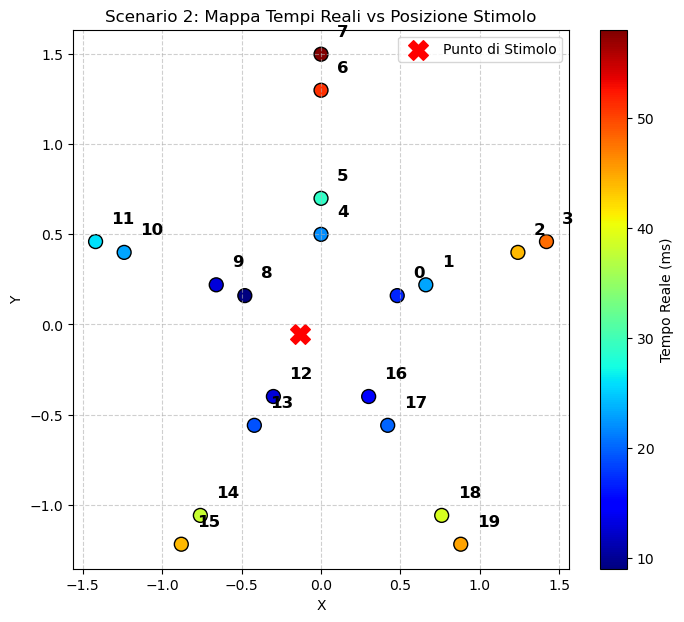

sim_rel [0.02309762 0.02504367 0.0322012  0.03467734 0.02697355 0.03003197
 0.03920752 0.04226606 0.02355419 0.02561722 0.0330113  0.03556692
 0.01458617 0.01352993 0.0142153  0.01603464 0.01406915 0.01277933
 0.01300491 0.01482126]
meas_rel [20. 22. 28. 30. 24. 27. 34. 36. 22. 25. 32. 35. 15. 16. 17. 18. 13. 12.
 13. 14.]
8.36293382688549
sim_rel2 [0.26652761 0.26856943 0.27682806 0.27960709 0.27338537 0.27609923
 0.28472284 0.28766835 0.27541093 0.2783081  0.28758289 0.29048988
 0.27169303 0.27431196 0.28283316 0.28578766 0.26382317 0.26571664
 0.27472253 0.27775592]
meas_rel2 [271. 273. 282. 285. 278. 281. 290. 293. 280. 283. 293. 296. 277. 282.
 295. 297. 265. 269. 279. 282.]
35.46621534367543
--- VERIFICA SPAZIALE SCENARIO 3 ---
Sensore | Tempo Reale (ms) | Distanza dallo Stimolo (mesh)
--------------------------------------------------
      0 |            20.00 |                    1.3784
      1 |            22.00 |                    1.5005
      2 |            28.00 |        

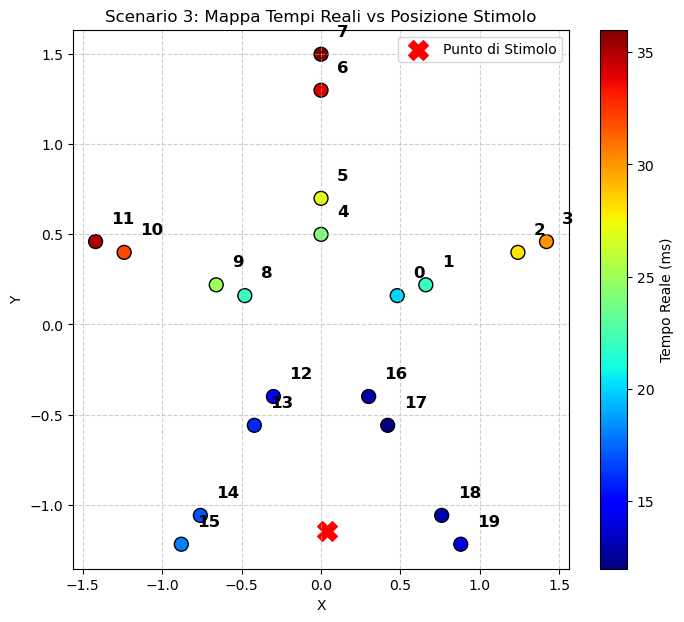

sim_rel [0.03363448 0.03568135 0.0428845  0.04535013 0.03666567 0.03970344
 0.04884706 0.05190134 0.03173524 0.03330718 0.03943767 0.041645
 0.02279977 0.02077805 0.01719551 0.01751214 0.02466291 0.02348966
 0.02246025 0.02330855]
meas_rel [33. 33. 38. 40. 34. 36. 43. 46. 29. 30. 35. 36. 21. 20. 16. 16. 24. 22.
 21. 22.]
11.697556670563323
sim_rel2 [0.28988488 0.28946581 0.2900848  0.29106256 0.29823517 0.30077639
 0.30880888 0.3115438  0.29935545 0.30205824 0.31076691 0.31354577
 0.29192115 0.29232281 0.2948362  0.29630081 0.2846557  0.28162022
 0.27270347 0.26988016]
meas_rel2 [296. 295. 296. 297. 305. 308. 315. 317. 306. 308. 316. 318. 297. 297.
 299. 301. 292. 287. 277. 274.]
31.81962914625949
--- VERIFICA SPAZIALE SCENARIO 4 ---
Sensore | Tempo Reale (ms) | Distanza dallo Stimolo (mesh)
--------------------------------------------------
      0 |            33.00 |                    1.7834
      1 |            33.00 |                    1.9128
      2 |            38.00 |        

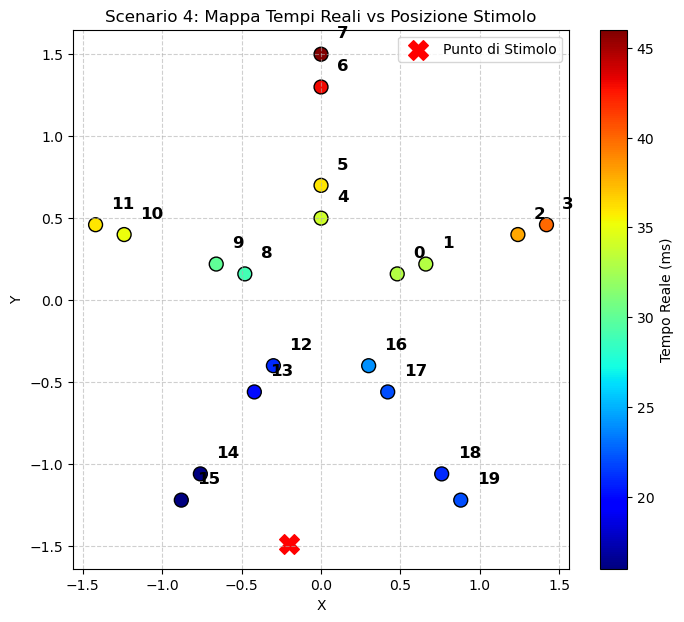

sim_rel [0.04097415 0.03818743 0.03036199 0.02819587 0.03635664 0.03202735
 0.02429705 0.02494127 0.04907916 0.0496062  0.05288127 0.05417225
 0.06171665 0.06690498 0.0829239  0.08814059 0.05790345 0.06198699
 0.07586828 0.0802181 ]
meas_rel [32. 30. 24. 22. 29. 26. 20. 20. 39. 39. 42. 43. 49. 53. 66. 70. 49. 57.
 69. 67.]
105.6829782473668
sim_rel2 [0.30494702 0.308121   0.31819211 0.32143316 0.31019744 0.31586627
 0.33330973 0.33921933 0.29776515 0.29871508 0.30308375 0.30509786
 0.28400191 0.27910246 0.26918367 0.27117931 0.29074665 0.28963303
 0.29178831 0.29462378]
meas_rel2 [322. 325. 334. 338. 327. 331. 347. 352. 315. 316. 321. 322. 302. 297.
 290. 294. 312. 315. 323. 321.]
376.40408188511117
--- VERIFICA SPAZIALE SCENARIO 5 ---
Sensore | Tempo Reale (ms) | Distanza dallo Stimolo (mesh)
--------------------------------------------------
      0 |            32.00 |                    1.5586
      1 |            30.00 |                    1.3994
      2 |            24.00 |      

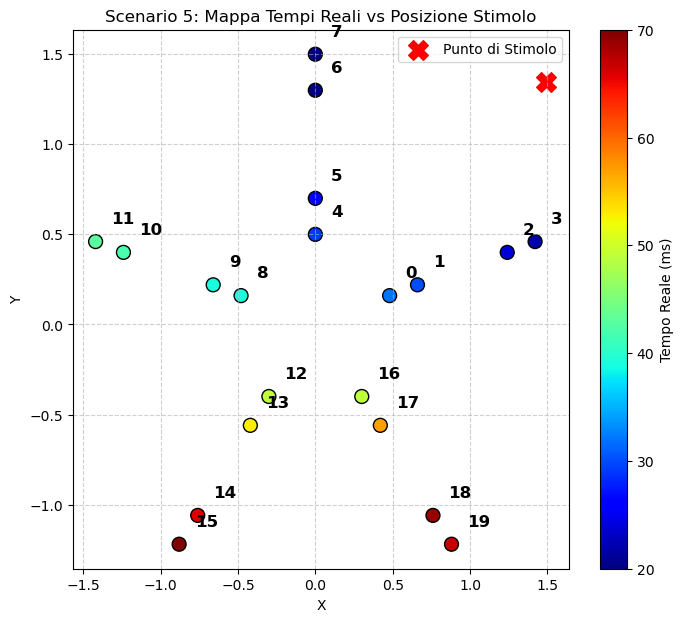

In [ ]:
a_ratios_training = np.load('checkpoint2anisotropy.npy')
signals = np.load('checkpoint2dataset.npy') 
impulse_sites = np.load('checkpoint2FocalPoints.npy')
starting_times = np.load('checkpoint2starting.npy') 
reference_targets = [
    [-0.407, 0.299, 0.578],
    [0.81, 0.113, 0.394],
    [-0.816, -0.686, 0.274],
    [0.197, -0.242, 0.042],
    [0.647, -0.69, 0.244]]

for idx in range(5):
    a_ratio = a_ratios_training[idx]**2
    xc, yc, r = reference_targets[idx]

    theta0 = np.pi/2 
    a = np.array([np.cos(theta0), np.sin(theta0)])
    b = np.array([np.cos(theta0-np.pi/2), np.sin(theta0-np.pi/2)])
    D = ((1/a_ratio)*np.outer(a, a) + np.outer(b, b))
    D_inv = np.linalg.inv(D)
    sigma_11, sigma_12, sigma_22 = D_inv[0,0], D_inv[0,1], D_inv[1,1]

    speed_field = lambda x, y: EST_V_SLOW if (x - xc)**2 + (y - yc)**2 <= r**2 else EST_V_BASE
    signals_event = signals[idx, :, :]
    x_0, y_0 = impulse_sites[idx][0]
    x_1, y_1 = impulse_sites[idx][1]
    t_0 = starting_times[idx][0]/1000
    t_1 = starting_times[idx][1]/1000

    # Simulazione BATTITO 1
    sim_beat1 = anisotropic_FMM_GPT(
        x_0, y_0, t_0, X_mesh_vel, Y_mesh_vel, speed_field, 
        sigma_11, sigma_12, sigma_22
    )

    sim_times1 = np.array([sim_beat1[i, j] for i, j in meas_indices_vel])
        
    # Simulazione BATTITO 2
    sim_beat2 = anisotropic_FMM_GPT(
        x_1, y_1, t_1, X_mesh_vel, Y_mesh_vel, speed_field, 
        sigma_11, sigma_12, sigma_22
    )

    sim_times2 = np.array([sim_beat2[i, j] for i, j in meas_indices_vel])

    meas_rel = measured_times_beat1[idx]
    print('sim_rel', sim_times1)
    print('meas_rel', meas_rel)
    print(np.mean((sim_times1*1e3 - meas_rel)**2))

    meas_rel2 = measured_times_beat2[idx]
    print('sim_rel2', sim_times2)
    print('meas_rel2', meas_rel2)
    print(np.mean((sim_times2*1e3 - meas_rel2)**2))

    x_stim, y_stim = impulse_sites[idx][0]

    # 2. Tempi reali (normalizzati)
    meas_rel = measured_times_beat1[idx] 

    # 3. Calcoliamo la distanza EUCLIDEA pura tra stimolo e sensori sulla tua mesh
    # Usiamo le coordinate estratte tramite i tuoi meas_indices_vel
    distanze_mesh = []
    for i, j in meas_indices_vel:
        d = np.sqrt((X_mesh_vel[i, j] - x_stim)**2 + (Y_mesh_vel[i, j] - y_stim)**2)
        distanze_mesh.append(d)

    distanze_mesh = np.array(distanze_mesh)

    # 4. Confronto
    print(f"--- VERIFICA SPAZIALE SCENARIO {idx+1} ---")
    print("Sensore | Tempo Reale (ms) | Distanza dallo Stimolo (mesh)")
    print("-" * 50)
    for s in range(20):
        print(f"{s:7d} | {meas_rel[s]:16.2f} | {distanze_mesh[s]:25.4f}")

    # 5. Correlazione
    correlation = np.corrcoef(meas_rel, distanze_mesh)[0, 1]
    print("-" * 50)
    print(f"Correlazione Tempo/Distanza: {correlation:.4f}")

    # Estraiamo gli indici i e j dalla tua lista di tuple
    meas_indices_vel_i = [idx[0] for idx in meas_indices_vel]
    meas_indices_vel_j = [idx[1] for idx in meas_indices_vel]

    plt.figure(figsize=(8,7))

    # Disegniamo i sensori colorandoli in base al tempo reale di attivazione
    sc = plt.scatter(X_mesh_vel[meas_indices_vel_i, meas_indices_vel_j], 
                    Y_mesh_vel[meas_indices_vel_i, meas_indices_vel_j], 
                    c=meas_rel, cmap='jet', s=100, edgecolors='k')
    # Disegniamo il punto di stimolo (focal point)
    plt.scatter(x_stim, y_stim, color='red', marker='X', s=200, label='Punto di Stimolo')

    # Aggiungiamo i numeri dei sensori per capire se l'ordine è quello che pensiamo
    for s in range(20):
        plt.text(X_mesh_vel[meas_indices_vel_i[s], meas_indices_vel_j[s]] + 0.1, 
                Y_mesh_vel[meas_indices_vel_i[s], meas_indices_vel_j[s]] + 0.1, 
                str(s), fontsize=12, fontweight='bold')

    plt.colorbar(sc, label='Tempo Reale (ms)')
    plt.title(f"Scenario {idx+1}: Mappa Tempi Reali vs Posizione Stimolo")
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.show()

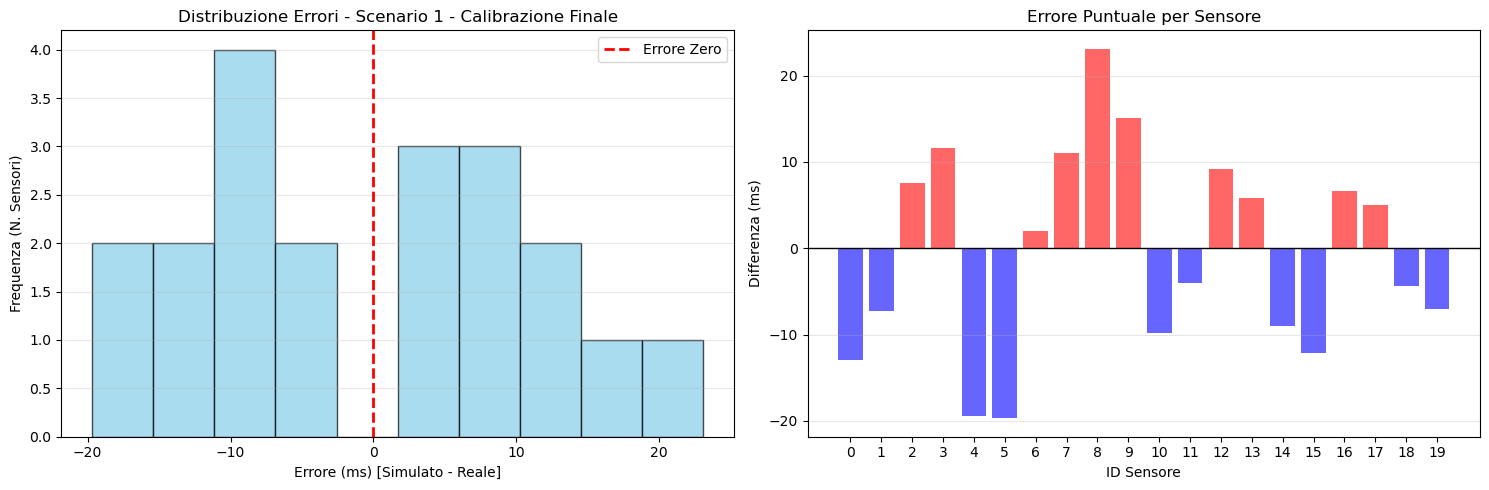

--- Statistiche Errore Scenario 1 - Calibrazione Finale ---
Errore Medio (Bias): -0.43 ms
Deviazione Standard: 11.52 ms
Errore Assoluto Medio (MAE): 10.13 ms


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

def plot_error_analysis(sim_rel, meas_rel, scenario_name="Scenario"):
    # Portiamo tutto in millisecondi per il confronto (sim_rel è in secondi)
    sim_ms = np.array(sim_rel) * 1000
    meas_ms = np.array(meas_rel)
    
    # Calcolo dell'errore (Residuo)
    errors = sim_ms - meas_ms
    
    fig, ax = plt.subplots(1, 2, figsize=(15, 5))
    
    # 1. Istogramma degli errori
    ax[0].hist(errors, bins=10, color='skyblue', edgecolor='black', alpha=0.7)
    ax[0].axvline(0, color='red', linestyle='dashed', linewidth=2, label='Errore Zero')
    ax[0].set_title(f'Distribuzione Errori - {scenario_name}')
    ax[0].set_xlabel('Errore (ms) [Simulato - Reale]')
    ax[0].set_ylabel('Frequenza (N. Sensori)')
    ax[0].legend()
    ax[0].grid(axis='y', alpha=0.3)

    # 2. Errore per singolo sensore
    sensor_ids = np.arange(len(errors))
    colors = ['red' if e > 0 else 'blue' for e in errors]
    ax[1].bar(sensor_ids, errors, color=colors, alpha=0.6)
    ax[1].axhline(0, color='black', linewidth=1)
    ax[1].set_title('Errore Puntuale per Sensore')
    ax[1].set_xlabel('ID Sensore')
    ax[1].set_ylabel('Differenza (ms)')
    ax[1].set_xticks(sensor_ids)
    ax[1].grid(axis='y', alpha=0.3)

    plt.tight_layout()
    plt.show()

    # Statistiche rapide
    print(f"--- Statistiche Errore {scenario_name} ---")
    print(f"Errore Medio (Bias): {np.mean(errors):.2f} ms")
    print(f"Deviazione Standard: {np.std(errors):.2f} ms")
    print(f"Errore Assoluto Medio (MAE): {np.mean(np.abs(errors)):.2f} ms")

# Esempio d'uso con i tuoi ultimi dati (Scenario 1 - Beat 1)
sim_test = [0.0251, 0.0277, 0.0366, 0.0396, 0.0446, 0.0403, 0.0530, 0.0580, 0.0621, 0.0541, 0.0342, 0.0370, 0.0092, 0.0058, 0.0, 0.0009, 0.0106, 0.0080, 0.0046, 0.0059]
meas_test = [38., 35., 29., 28., 64., 60., 51., 47., 39., 39., 44., 41., 0., 0., 9., 13., 4., 3., 9., 13.]

plot_error_analysis(sim_test, meas_test, "Scenario 1 - Calibrazione Finale")

### signature of the function ###

In [ ]:
from tqdm import tqdm

def find_best_start(patient_cost_func):
    print("🚀 Scanning globale dello spazio (Pos, R, Aniso)...")
    best_mse = float('inf')
    best_params = [0, 0, 0.5, 5.0]
    mse_l = patient_cost_func([-0.407, 0.299, 0.578, 2.0])

    
    # Generiamo 30 combinazioni casuali entro i bounds
    # x, y in [-1.8, 1.8], r in [0.2, 1.2], aniso in [2, 5]
    np.random.seed(42) # Per ripetibilità
    random_starts = np.random.uniform(
        low=[-1.5, -1.5, 0.2, 2.0], 
        high=[1.5, 1.5, 0.8, 5.0], 
        size=(20, 4)
    )

    mse_l = patient_cost_func([-0.407, 0.299, 0.578, 2.0])
    print(f"Reference target MSE: {mse_l:.4f}")

    
    for p in random_starts:
        mse = patient_cost_func(p)
        print(f"Tested start: Pos=({p[0]:.2f}, {p[1]:.2f}), R={p[2]:.2f}, Aniso={p[3]:.1f} -> MSE={mse:.4f}")
        if mse < best_mse:
            best_mse = mse
            best_params = p
            
    print(f"📍 Punto di partenza ottimale trovato: Pos={best_params[:2]}, R={best_params[2]:.2f}, Aniso={best_params[3]:.1f}")
    return best_params

# ==========================================
# 7. FUNZIONE FINALE (FASE 2) - VERSIONE OTTIMIZZATA
# ==========================================
def GroupSolutionCP2(signals_event, x_0, y_0, t_0, x_1, y_1, t_1):
    global EST_V_BASE, EST_V_SLOW
    
    # --- 1. ESTRAZIONE TEMPI (CORRETTA) ---
    raw_timings = GroupSolutionCP1(signals_event)

    # Creiamo liste temporanee per riordinare i dati
    t_beat1_ordered = []
    t_beat2_ordered = []

    # Iteriamo su ogni spline (5 spline in totale)
    for s in range(5):
        # Estraiamo i 4 sensori della spline corrente (es. sensori 0,1,2,3)
        spline_chunk = raw_timings[s*4 : (s+1)*4]
        
        # INVERTIAMO l'ordine radiale del blocco: 
        # se era [1.5, 1.3, 0.7, 0.5] diventa [0.5, 0.7, 1.3, 1.5]
        # per combaciare con il tuo Spline_spacing e meas_indices_vel
        spline_chunk_reversed = spline_chunk[::-1]
        
        for t in spline_chunk_reversed:
            t_beat1_ordered.append(t[0])
            t_beat2_ordered.append(t[1])

        meas_beat1 = np.array(t_beat1_ordered, dtype=float)
        meas_beat2 = np.array(t_beat2_ordered, dtype=float)
    
    # --- 2. ALLINEAMENTO ---
    t_0 = t_0 / 1000
    t_1 = t_1 / 1000

    # --- 3. FUNZIONE DI OTTIMIZZAZIONE ---
    def patient_cost(params):
        xc, yc, r, a_ratio_square = params
        a_ratio = a_ratio_square**2  
        total_mse = 0.0
        
        # Parametro di ripidezza per la transizione (k=50 è un ottimo standard)
        # k = 50.0
                
        # Tensore di diffusione
        theta0 = np.pi/2 
        a = np.array([np.cos(theta0), np.sin(theta0)])
        b = np.array([np.cos(theta0-np.pi/2), np.sin(theta0-np.pi/2)])
        D = ((1/a_ratio)*np.outer(a, a) + np.outer(b, b))
        D_inv = np.linalg.inv(D)
        sigma_11, sigma_12, sigma_22 = D_inv[0,0], D_inv[0,1], D_inv[1,1]
        
        # --- MODIFICA VELOCITÀ SFUMATA (TANH) ---
        # Calcolo distanza continua di ogni nodo dal centro xc, yc
        # dist = np.sqrt((X_mesh_vel - xc)**2 + (Y_mesh_vel - yc)**2)
        
        # Calcolo del peso (0 dentro l'ischemia, 1 fuori)
        # weight = 0.5 * (1 + np.tanh(k * (dist - r)))
        
        # Generazione matrice velocità continua
        # speed_grid = EST_V_SLOW + weight * (EST_V_BASE - EST_V_SLOW)
        
        speed_field = lambda x, y: EST_V_SLOW if (x - xc)**2 + (y - yc)**2 <= r**2 else EST_V_BASE

        # Simulazione BATTITO 1
        sim_beat1 = anisotropic_FMM_GPT(
            x_0, y_0, t_0, X_mesh_vel, Y_mesh_vel, speed_field, 
            sigma_11, sigma_12, sigma_22
        ) * 1000.0         
        
        sim_times1 = np.array([sim_beat1[i, j] for i, j in meas_indices_vel])
        sim_times1 = sim_times1
        mask1 = ~np.isnan(meas_beat1)
        if np.any(mask1):
            total_mse += np.mean((sim_times1[mask1] - meas_beat1[mask1])**2)
            
        # Simulazione BATTITO 2
        sim_beat2 = anisotropic_FMM_GPT(
            x_1, y_1, t_1, X_mesh_vel, Y_mesh_vel, speed_field, 
            sigma_11, sigma_12, sigma_22
        ) * 1000.0 
        
        sim_times2 = np.array([sim_beat2[i, j] for i, j in meas_indices_vel])
        sim_times2 = sim_times2
        mask2 = ~np.isnan(meas_beat2)
        if np.any(mask2):
            total_mse += np.mean((sim_times2[mask2] - meas_beat2[mask2])**2)
            
        return total_mse

    # --- 4. ESECUZIONE ---
    initial_guess = find_best_start(patient_cost)
    bounds = [(-2.0, 2.0), (-2.0, 2.0), (0.01, 1.5), (1.0, 5.0)]
    
    res_patient = minimize(patient_cost, initial_guess, method='Nelder-Mead', bounds=bounds, options={
        'xatol': 0.001,
        'fatol': 0.0001,
        'maxiter': 150,
        'adaptive': True
    })
    
    print(f'Anisotropia: {res_patient.x[3]:.2f}')
    return [res_patient.x[0], res_patient.x[1], res_patient.x[2]]

In [ ]:
# ==========================================
# TEST RAPIDO SUL PRIMO PAZIENTE (SCENARIO 1)
# ==========================================

print("=== AVVIO TEST SINGOLO (Scenario 1) ===\n")

# Indice 0 corrisponde al primo scenario
idx = 0

# 1. Estrazione dati
signals_event = signals[idx, :, :]
x_0, y_0 = impulse_sites[idx][0]
x_1, y_1 = impulse_sites[idx][1]
t_0 = starting_times[idx][0]
t_1 = starting_times[idx][1]
true_x, true_y, true_r = reference_targets[idx]

# 2. Avvio predizione (vedrai apparire la barra di caricamento qua sotto)
print("Avvio simulazione. Elaborazione in corso...\n")
predicted_target = GroupSolutionCP2(signals_event, x_0, y_0, t_0, x_1, y_1, t_1)
pred_x, pred_y, pred_r = predicted_target

# 3. Calcolo e stampa degli errori
center_err = np.sqrt((pred_x - true_x)**2 + (pred_y - true_y)**2)
r_err = abs(pred_r - true_r)

print(f"\n✅ Test Completato!")
print(f"Target Reale  : Centro [{true_x:6.3f}, {true_y:6.3f}], Raggio: {true_r:5.3f}")
print(f"Target Stimato: Centro [{pred_x:6.3f}, {pred_y:6.3f}], Raggio: {pred_r:5.3f}")
print(f"Errore Centro : {center_err:.4f} cm")
print(f"Errore Raggio : {r_err:.4f} cm")

=== AVVIO TEST SINGOLO (Scenario 1) ===

Avvio simulazione. Elaborazione in corso...

🚀 Scanning globale dello spazio (Pos, R, Aniso)...
Reference target MSE: 141.9080
Tested start: Pos=(-0.38, 1.35), R=0.64, Aniso=3.8 -> MSE=2462.5661
Tested start: Pos=(-1.03, -1.03), R=0.23, Aniso=4.6 -> MSE=4534.1247
Tested start: Pos=(0.30, 0.62), R=0.21, Aniso=4.9 -> MSE=5692.4923
Tested start: Pos=(1.00, -0.86), R=0.31, Aniso=2.6 -> MSE=346.2921
Tested start: Pos=(-0.59, 0.07), R=0.46, Aniso=2.9 -> MSE=660.2827
Tested start: Pos=(0.34, -1.08), R=0.38, Aniso=3.1 -> MSE=945.7226
Tested start: Pos=(-0.13, 0.86), R=0.32, Aniso=3.5 -> MSE=1677.7018
Tested start: Pos=(0.28, -1.36), R=0.56, Aniso=2.5 -> MSE=588.4719
Tested start: Pos=(-1.30, 1.35), R=0.78, Aniso=4.4 -> MSE=3947.7325
Tested start: Pos=(-0.59, -1.21), R=0.61, Aniso=3.3 -> MSE=1841.8009
Tested start: Pos=(-1.13, -0.01), R=0.22, Aniso=4.7 -> MSE=5009.5763
Tested start: Pos=(-0.72, 0.49), R=0.39, Aniso=3.6 -> MSE=1689.9955
Tested start: Pos=

KeyboardInterrupt: 